# Vision — Denoising dengan Autoencoder Konvolusi
**Kapan dipakai:** gambar berbintik/berderau (foto gelap, scan jelek) harus dibersihkan, atau
sebagai praproses sebelum klasifikasi/OCR.

**Langkah:** latih autoencoder dengan input = gambar bersih + derau Gaussian (`NOISE_SIGMA`),
target = gambar bersih → ukur PSNR gambar berderau vs hasil (makin tinggi makin baik).
Tidak butuh label kelas.

**Data demo:** CIFAR-10 kecil.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.nn import functional

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
NOISE_SIGMA = 0.1     # kekuatan derau (0–1)
EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 0.001
SEED = 42
torch.manual_seed(SEED)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data + ubah gambar jadi tensor
Tensor gambar: (jumlah, 3 warna, tinggi, lebar), nilai 0–1.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)


def load_images(paths):
    arrays = []
    for path in paths:
        arrays.append(np.asarray(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB")))
    images = torch.tensor(np.stack(arrays))
    return images.permute(0, 3, 1, 2).float() / 255


X_train = load_images(train[PATH_COL])
X_test = load_images(test[PATH_COL])
print("latih:", X_train.shape, "| test:", X_test.shape)

train: (4000, 2) | test: (1000, 2)


latih: torch.Size([4000, 3, 32, 32]) | test: torch.Size([1000, 3, 32, 32])


## Model: autoencoder konvolusi kecil

In [4]:
net = nn.Sequential(
    nn.Conv2d(3, 32, 3, padding=1),
    nn.ReLU(),
    nn.Conv2d(32, 64, 3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1),
    nn.ReLU(),
    nn.ConvTranspose2d(64, 32, 2, stride=2),
    nn.ReLU(),
    nn.Conv2d(32, 3, 3, padding=1),
    nn.Sigmoid(),
)
net = net.to(DEVICE)

## Latih (input berderau, target bersih)

In [5]:
optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
for epoch in range(EPOCHS):
    order = torch.randperm(len(X_train))
    for start in range(0, len(order), BATCH_SIZE):
        clean = X_train[order[start:start + BATCH_SIZE]].to(DEVICE)
        noisy = clean + NOISE_SIGMA * torch.randn_like(clean)
        noisy = noisy.clamp(0, 1)
        loss = functional.mse_loss(net(noisy), clean)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print("epoch", epoch + 1, "loss", round(loss.item(), 5))

epoch 1 loss 0.01188


epoch 2 loss 0.00664


epoch 3 loss 0.00543


epoch 4 loss 0.0067


epoch 5 loss 0.00454


...

epoch 16 loss 0.00244


epoch 17 loss 0.0022


epoch 18 loss 0.00244


epoch 19 loss 0.0022


epoch 20 loss 0.0023


## Evaluasi: PSNR di data test (derau dibuat sekali dengan seed tetap)
PSNR = -10 × log10(MSE). Naik 3 dB ≈ error turun setengah.

In [6]:
torch.manual_seed(SEED)
net.eval()
clean_test = X_test.to(DEVICE)
noisy_test = clean_test + NOISE_SIGMA * torch.randn_like(clean_test)
noisy_test = noisy_test.clamp(0, 1)
with torch.no_grad():
    denoised = net(noisy_test)

noisy_mse = ((noisy_test - clean_test) ** 2).mean(dim=(1, 2, 3))
denoised_mse = ((denoised - clean_test) ** 2).mean(dim=(1, 2, 3))
psnr_noisy = (-10 * torch.log10(noisy_mse)).cpu().numpy()
psnr_denoised = (-10 * torch.log10(denoised_mse)).cpu().numpy()
print("PSNR berderau:", round(psnr_noisy.mean(), 2))
print("PSNR denoised:", round(psnr_denoised.mean(), 2))

PSNR berderau: 20.33
PSNR denoised: 26.73


## Contoh: bersih / berderau / hasil

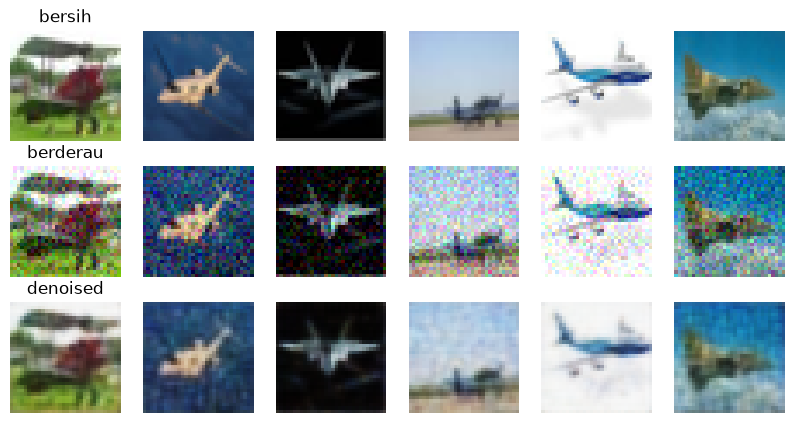

In [7]:
fig, axes = plt.subplots(3, 6, figsize=(10, 5))
for column in range(6):
    axes[0, column].imshow(X_test[column].permute(1, 2, 0))
    axes[1, column].imshow(noisy_test[column].cpu().permute(1, 2, 0))
    axes[2, column].imshow(denoised[column].cpu().permute(1, 2, 0))
    axes[0, column].axis("off")
    axes[1, column].axis("off")
    axes[2, column].axis("off")
axes[0, 0].set_title("bersih")
axes[1, 0].set_title("berderau")
axes[2, 0].set_title("denoised")
plt.show()

## Hasil per gambar

In [8]:
result = pd.DataFrame()
result["id"] = test["id"]
result["psnr_berderau"] = psnr_noisy
result["psnr_denoised"] = psnr_denoised
result.to_csv("hasil.csv", index=False)
result.head()

,id,psnr_berderau,psnr_denoised
0,1,20.519592,25.536329
1,2,20.390839,26.576973
2,3,22.079643,27.297533
3,4,20.138859,29.333931
4,5,21.846092,25.548996
